---
title: "Infographic Design Elements"
subtitle: "DS 2023 | Communicating with Data"
---

<img src="https://virginia.box.com/shared/static/hdulrc8oiimvg0afhzexpxs4s9an9i26.png" style="height:500px;">

## Overview

An **infographic** combines visual elements &mdash; charts, large numbers, short text, icons, and a layout &mdash; into one composition that tells a **story**.

It walks a reader through an **argument**, one visual element at a time.

In contrast to notebooks, which are designed for exploration, infographics are **explanatory**.

The analyst has already found something, and the infographic's job is to make a reader understand it quickly, believe it, and remember it.

Infographics introduce some new design elements that we have not seen yet. 

For example, this notebook adds **big numbers**, **unit charts** (waffles and pictograms), and **layout** as a tool for telling a story in order.

```{note}
An infographic is not a dashboard.

A dashboard is interactive and can be multipurpose. 

An infographic is built for one reading: it states a finding and makes the case for it.
```

## Use Cases

**News and magazine graphics**: a full-page explainer of an election, a storm, or a budget.

**Public health and safety**: posters about vaccination rates, hand washing, or the signs of a stroke.

**Reports for the public**: the one-page summary at the front of an annual report or a census release.

**Science communication**: a visual abstract of a paper, or a poster at a conference.

**Social media**: a single tall image, meant to be read on a phone in a few seconds.

**Classrooms and museums**: a wall panel that a visitor reads standing up.

```{note}
These all have in common the need to send a **clear message** to a **known audience** in an **established medium**.
```

## A Short History

Infographics are older than the word.

**William Playfair**, whom we met in *Area Charts*, published charts with explanatory text and labels in his *Commercial and Political Atlas* (1786).

**Florence Nightingale** used her *Diagram of the Causes of Mortality in the Army in the East* (1858) to persuade officials that more soldiers in the Crimean War were dying of preventable disease than of wounds.

**Charles Joseph Minard**'s map of Napoleon's march on Moscow (1869) combines a map, a flow, a temperature line, and dates in a single image.

**W. E. B. Du Bois** and his students at Atlanta University made dozens of hand-drawn data portraits of Black life in America for the 1900 Paris Exposition, many of them bold, colorful, and built for viewers who had never thought about the subject.

```{note} Historical Note

In 1920s Vienna, **Otto Neurath**, **Marie Reidemeister** (later Marie Neurath), and the artist **Gerd Arntz** created **Isotype**, a system of picture statistics for the general public.

Isotype's main rule is that **a symbol stands for a fixed quantity**, and larger quantities are shown with *more* symbols, never with *bigger* ones.

Marie Neurath gave the work of turning data into a picture a name: the **transformer**, the person who decides what the reader most needs to see.
```

## The Anatomy of an Infographic

Most infographics are built from the same parts.

| Part | What it does | Our tool |
|---|---|---|
| **Headline** | states the story in one line, as an active title | `fig.text()`, large and bold |
| **Subtitle** (or "dek") | one or two sentences of context under the headline | `fig.text()`, smaller and gray |
| **Big number** | a single striking figure, with a short label | a text-only axes |
| **Modules** | the sections of the story, each with its own small title | axes in a mosaic |
| **Charts** | the evidence in each module | Pandas `.plot` |
| **Unit charts** | counts made visible as squares or icons | `plot.scatter` with square or custom markers |
| **Annotations** | labels and callouts that say what to notice | `text()`, `annotate()`, `bar_label()` |
| **Source and credit** | where the data came from, and who made the graphic | `fig.text()`, small and gray |

The parts are arranged in a **reading order**.

Readers of English start at the top left and move down, so the headline goes at the top, the strongest evidence next, and the details and source last.

## The data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.path import Path # Matplotlib’s basic description of a shape

In [2]:
titanic = sns.load_dataset('titanic')
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


We will build one infographic, about who survived the sinking of the *Titanic* in 1912.

The `titanic` dataset has one row per passenger.

## The question

As we saw earlier in this course, the dataset tells a story of who survived the disaster. 

It provided data to answer: **What characteristics of a person contributed to their survival?**

Based on what we already know about the data, the columns we will focus on are `survived`, `sex`, and `class`.

## What's the story?

A good infographic starts with a question, not a chart.

Before drawing anything, we write down the story we want to tell.

The we gather the claims that support it.

**Story:** *On the Titanic, a passenger's sex and ticket class largely determined who lived.*

**Claims:**

1. Fewer than four in ten passengers survived.
2. Most women survived, and most men did not.
3. Survival fell with ticket class.
4. The gap is widest between first-class women and third-class men.

Each claim will become one module.

Let's analyze the data to support the story and the claimns.

In [3]:
overall = titanic.survived.mean()
by_sex = titanic.groupby('sex').survived.mean()
by_class = titanic.groupby('class', observed=True).survived.mean()
by_class_sex = titanic.pivot_table(
    index='class', columns='sex', values='survived',
    aggfunc=['sum','mean'], observed=True)

In [4]:
print("Number of passengers in dataset:", len(titanic))
print("Number of survivors in dataset:", int(len(titanic) * overall))
print("Survival rate", str(int(overall.round(2) * 100))+'%')

Number of passengers in dataset: 891
Number of survivors in dataset: 342
Survival rate 38%


In [5]:
by_sex.round(2).to_frame()

,survived
sex,
female,0.74
male,0.19


In [6]:
by_class.round(2).to_frame()

,survived
class,
First,0.63
Second,0.47
Third,0.24


In [7]:
by_class_sex.round(2)

sum        mean      
sex    female male female  male
class                          
First      91   45   0.97  0.37
Second     70   17   0.92  0.16
Third      72   47   0.50  0.14

All four claims hold.

Notice how large the extremes are: 97% of first-class women survived, and 14% of third-class men.

That contrast is the most striking fact in the data, so it deserves the most prominent place.

```{caution}
The story says sex and class *decided* who lived, which is a strong word.

It is fair here because the history is well documented: the crew loaded lifeboats under a rule of "women and children first," and third-class passengers had the longest way to the boats.

Without that history, the data alone would only support *were associated with*.
```

## Building Block 1: The Big Number

Many infographics open with **a single large number**.

A **big number** gives the reader a place to focus.

We define a function to create these as needed.

In [8]:
# First, we define some colors to use throughout
ACCENT = '#1f6f8b' # Cyan
MUTED = '#d0d0d0' # Gray

def big_number(ax, value, label, color=ACCENT):
    """Show a large number above a short label in an empty axes."""
    ax.set_axis_off() # Lose all the spines, etc.

    # The value  
    ax.text(0, 0.55, value, fontsize=40, fontweight='bold', color=color,
            transform=ax.transAxes, va='bottom')

    # The label
    ax.text(0, 0.45, label, fontsize=11, color='dimgray',
            transform=ax.transAxes, va='top')

Now we create a row of key numbers.

These are often KPI -- key performance indicators -- in other infographics.

### The number row

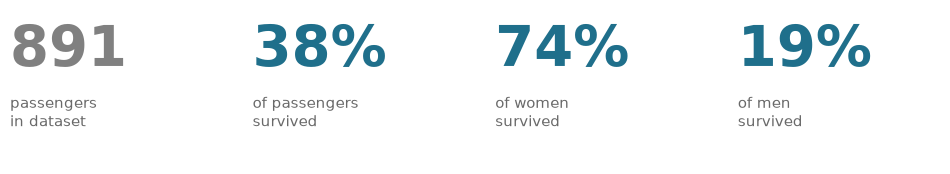

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(12, 2))

big_number(ax[0], f'{len(titanic)}', 'passengers\nin dataset', 'gray')
big_number(ax[1], f'{overall:.0%}', 'of passengers\nsurvived')
big_number(ax[2], f'{by_sex.female:.0%}', 'of women\nsurvived')
big_number(ax[3], f'{by_sex.male:.0%}', 'of men\nsurvived')

plt.show()

### About the use of the accent color

The three numbers about survival are in the accent color.

This is because in this infographic, the accent color will mean one thing: *survived*.

## Building Block 2: The Waffle Chart

All percentages are easy to understand, a more powerful way of presenting them is visually.

We could use a bar for this, but a more effective way is to use a **waffle chart**.

A waffle chart consists of a square grid of $100$ little squares. 

Each little square stands for a percentage point, with the share we care about filled in.

This makes the percentage visually **countable**.

### Creating a waffle chart from scratch

A waffle is a scatter plot of discrete data and square-shaped points.

We can build one in the following way.

In [10]:
# Get the percentage of interest, in this case womem
pct = round(by_sex.female * 100)

# Generate a dataframe of percentage points
cells = pd.DataFrame({'cell': range(100)})

# Identify the location of the cell in the 10 x 10 grid
cells['row'] = cells.cell // 10
cells['col'] = cells.cell % 10

# Identify the cells to accent
cells['filled'] = cells.cell < pct

cells.head()

,cell,row,col,filled
0,0,0,0,True
1,1,0,1,True
2,2,0,2,True
3,3,0,3,True
4,4,0,4,True


Now we draw the empty and filled squares as two scatter plots on the same axes, with square markers.

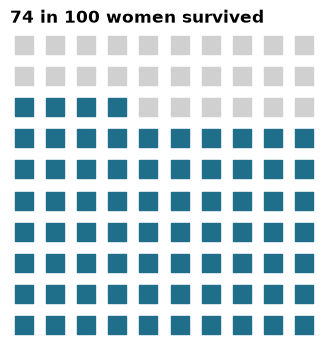

In [11]:
fig, ax = plt.subplots(figsize=(4, 4))

# The unaccented cells
cells[~cells.filled].plot.scatter(x='col', y='row', marker='s', s=180, color=MUTED, ax=ax)

# The accented cells
cells[cells.filled].plot.scatter(x='col', y='row', marker='s', s=180, color=ACCENT, ax=ax)

# Make square and remove crufy
ax.set_aspect('equal')
ax.set_axis_off()

# Add title
ax.set_title(f'{pct} in 100 women survived', loc='left', fontweight='bold')

# And voila
plt.show()

The axes are turned off because rows and columns mean nothing here; only the count of squares does.

`set_aspect('equal')` keeps the grid square, so each cell is the same size.

### A general function

Now let's put this in a function, so we can draw a waffle for any share on any axes.

In [12]:
def waffle(ax, share, title, color=ACCENT, size=150):
    """Draw a 10 x 10 waffle chart with round(share * 100) filled squares."""
    
    n = round(share * 100)
    cells = pd.DataFrame({'cell': range(100)})
    cells['row'] = cells.cell // 10
    cells['col'] = cells.cell % 10
    cells['filled'] = cells.cell < n

    cells[~cells.filled].plot.scatter(x='col', y='row', marker='s', s=size, color=MUTED, ax=ax)
    cells[cells.filled].plot.scatter(x='col', y='row', marker='s', s=size, color=color, ax=ax)

    ax.set_aspect('equal')
    ax.set_axis_off()
    ax.set_title(title, loc='left', fontweight='bold', fontsize=12)

To compare two groups, we put two waffles side by side.

We loop over a list of groups with `enumerate()` and reach the axes by index.

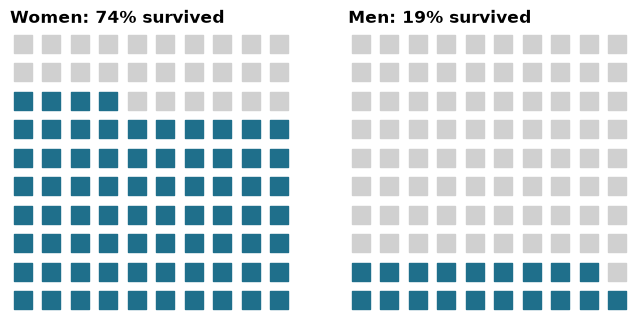

In [13]:
groups = by_sex.index # ['female', 'male']
labels = ['Women', 'Men']

fig, ax = plt.subplots(1, len(groups), figsize=(4*len(groups), 4))

# Create one waffle for each of the two groups
for i, group in enumerate(groups):
    waffle(
        ax[i], 
        by_sex[group], # The percentage associatd with the group
        f'{labels[i]}: {by_sex[group]:.0%} survived'
    )

plt.show()

Side by side, the two grids make the difference between 74 squares and 19 squares something a reader can *see*, not just read.

```{tip}
Waffles work for one share or a few shares that add to 100%.

They are a good replacement for a pie chart, since counting squares is easier than judging angles.

With more than four or five categories, use a sorted bar chart instead.
```

## Building Block 3: Pictograms

A **pictogram** is a unit chart with icons instead of squares.

Isotype's rule states that each icon stands for a fixed number of people or things, and that bigger quantities get **more icons**, not **bigger icons**.

Let's see why the rule matters before we follow it.

### Making an icon from scratch

Matplotlib can create arbitrary shapes with `Path`.

A shape can then be used as a marker in a plot.

A path is a just list of points and instructions for joining them. 

Let's use them to draw a simple person from a circle for the head and a polygon for the body.

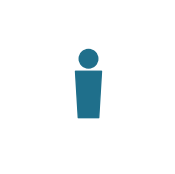

In [14]:
head = Path.circle(center=(0, 0.62), radius=0.2)
body = Path([(-0.28, 0.35), (0.28, 0.35), (0.22, -0.65), (-0.22, -0.65), (-0.28, 0.35)],
            [Path.MOVETO, Path.LINETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY])

# This joins the two shapes into one marker
person = Path.make_compound_path(head, body)

# To show what we have created, we plot a simple  
# dataframe, with one data point, using the person as a marker
icon = pd.DataFrame({'x': [0], 'y': [0]})
ax = icon.plot.scatter(x='x', y='y', marker=person, s=3000, color=ACCENT, figsize=(2, 2))
ax.set_axis_off()
plt.show()

### When icons mislead: scaling

Let's use our icon to demonstrate a design principle.

Let's compare the number of passengers in first and third class.

Third class had about 2.3 times as many passengers.

The tempting picture is one icon per class, with its *height* scaled to the count.

In [15]:
counts = titanic['class'].value_counts().sort_index()

ratio = counts.Third / counts.First
print(f'Third class / first class: {ratio:.2f} times as many passengers')
print(f'Area of a scaled icon:     {ratio ** 2:.2f} times as large')

Third class / first class: 2.27 times as many passengers
Area of a scaled icon:     5.17 times as large


A marker's size `s` in Matplotlib is an **area**, in points squared.

If the icon's height grows by 2.27, its area grows by 2.27², or 5.17.

The reader sees the area.

In [16]:
# We create a dataframe of class counts
# along with their positions in a plot
scaled = pd.DataFrame({
    'x': [0, 1, 2], 
    'y': [0, 0, 0], 
    'count': counts.values}
)
# We compute the size of the icon 
# This is a function of the size of the first value
scaled['s'] = 1200 * (scaled['count'] / counts.First) ** 2
scaled

,x,y,count,s
0,0,0,216,1200.000000
1,1,0,184,870.781893
2,2,0,491,6200.643004


Now we plot our data two ways.

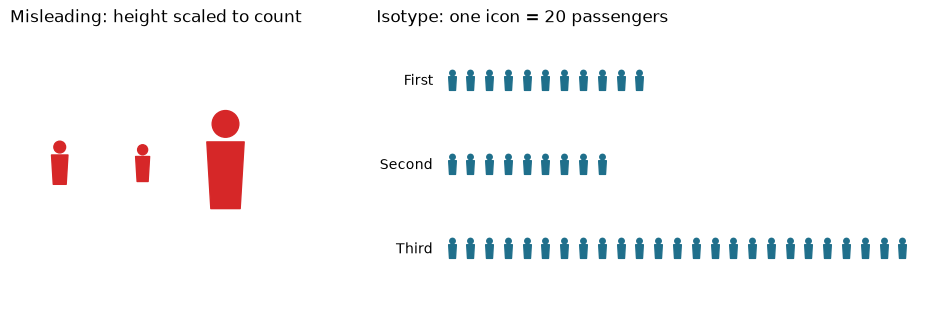

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), width_ratios=[1, 2])

# Method one: Each row is an icon, differeing by size s

scaled.plot.scatter(x='x', y='y', s='s', marker=person, color='tab:red', ax=ax[0])
ax[0].set_xlim(-0.6, 2.8)
ax[0].set_axis_off()
ax[0].set_title('Misleading: height scaled to count', loc='left')

# Method two: Each row is represented by a series of icons differing by length

# First, build a dataframe
per_icon = 20 # to reduce the number of icons; each icon represents 20 people
rows = []
for i, cls in enumerate(counts.index):
    n_icons = round(counts.iloc[i] / per_icon)
    rows.append(pd.DataFrame({'x': range(n_icons), 'y': [-i] * n_icons}))
repeated = pd.concat(rows)
# print(repeated)

repeated.plot.scatter(x='x', y='y', marker=person, s=260, color=ACCENT, ax=ax[1])

# Add labels
for i, cls in enumerate(counts.index):
    ax[1].text(-1, -i, cls, ha='right', va='center')
    
ax[1].set_xlim(-4, 26)
ax[1].set_ylim(-2.6, 0.6)
ax[1].set_axis_off()
ax[1].set_title(f'Isotype: one icon = {per_icon} passengers', loc='left')

plt.show()

On the left, the third-class icon looks about five times bigger than the first-class icon, when the real ratio is about two.

On the right, a reader can count: 11 icons, 9 icons, 25 icons.

The repeated icons are **honest** because length, not area, carries the number, just as in a bar chart.

A row of icons *is* a bar chart, with the bar cut into countable pieces.

```{note}
Rounding to whole icons loses a little precision: 216 first-class passengers become 11 icons, or 220.

That is acceptable when the icon's value is stated and the comparison is the point.

When the exact numbers matter, put them in the labels.
```

### A pictogram that tells the story

Now let's color each icon by outcome, so each row shows both how many passengers were in a class and how many of them survived.

We count survivors and deaths in each class, convert them to icons, and build one row per class.

In [18]:
outcomes = (titanic
            .groupby(['class', 'survived'], observed=True)
            .size()
            .unstack()
            .rename(columns={0: 'died', 1: 'survived'}))

icons = (outcomes / per_icon).round().astype(int)
icons

survived,died,survived
class,,
First,4,7
Second,5,4
Third,19,6


In [19]:
def pictogram(ax, icons, per_icon, size=320):
    """One row of icons per group: survivors first, in the accent color, then deaths in gray."""
    rows = []
    for i, group in enumerate(icons.index):
        n_lived = icons.loc[group, 'survived']
        n_died = icons.loc[group, 'died']
        rows.append(pd.DataFrame({'x': range(n_lived + n_died),
                                  'y': [-i] * (n_lived + n_died),
                                  'lived': [True] * n_lived + [False] * n_died}))
    grid = pd.concat(rows)

    grid[grid.lived].plot.scatter(x='x', y='y', marker=person, s=size, color=ACCENT, ax=ax)
    grid[~grid.lived].plot.scatter(x='x', y='y', marker=person, s=size, color=MUTED, ax=ax)

    for i, group in enumerate(icons.index):
        ax.text(-1, -i, group, ha='right', va='center', fontsize=11)

    ax.set_xlim(-4, icons.sum(axis=1).max() + 1)
    ax.set_ylim(-len(icons) + 0.4, 0.6)
    ax.set_axis_off()

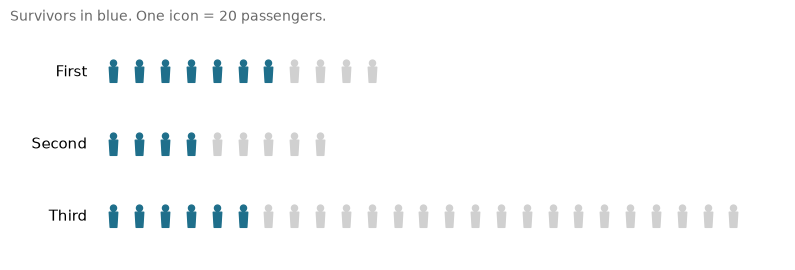

In [20]:
fig, ax = plt.subplots(figsize=(10, 3))
pictogram(ax, icons, per_icon)
ax.set_title(f'Survivors in blue. One icon = {per_icon} passengers.', loc='left', color='dimgray', fontsize=10)
plt.show()

Now one picture shows two things at once.

The rows grow longer as we go down, because third class was the largest.

The blue share shrinks as we go down, because survival fell with class.

Notice that survivors come first in each row, so all the blue starts at the same left edge, like the bars of a stacked bar chart.

What would the reader lose if the blue and gray icons were shuffled within each row?

## Building Block 4: A Chart with Emphasis

Our last claim compares six groups: each class, split by sex.

That is a job for an ordinary bar chart, sorted, with the extremes picked out in color, as in *From Bad to Better*.

First, let's shape the data: stack the class-by-sex table into one Series with readable labels.

In [21]:
rates

NameError: name 'rates' is not defined

In [ ]:
rates = by_class_sex.stack()['mean']
rates.index = [f'{cls} class, {"women" if sex == "female" else "men"}' for cls, sex in rates.index]
rates = rates.sort_values()
rates

In [ ]:
colors = [MUTED] * len(rates)
colors[0] = ACCENT
colors[-1] = ACCENT

ax = rates.plot.barh(color=colors, width=0.75, figsize=(8, 3.5))
ax.bar_label(ax.containers[0], labels=[f'{r:.0%}' for r in rates], padding=4, fontsize=10)

ax.set_xlim(0, 1.1)
ax.xaxis.set_visible(False)
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.set_title('97% of first-class women survived; 14% of third-class men did', loc='left', fontweight='bold')
plt.show()

Note that the bars start at zero, as all bars should.

The x axis is hidden because every bar is labeled with its value; the axis would only repeat the labels.

The title states the contrast, and the two bars in the accent color are the evidence for it.

The other four bars are gray, not because they do not show survival, but because they are context for the two that make the point.

## Layout: Putting the Modules in Order

We now have four modules, one per claim.

An infographic arranges them on a grid, in the order the story should be read.

`plt.subplot_mosaic()`, from *Subplots and Mosaics*, is the right tool, since each module can span as many columns as it needs.

Let's sketch the layout first, with each module labeled by name.

In [ ]:
layout = [
    ['big1', 'big1', 'big2', 'big2', 'big3', 'big3', 'big4', 'big4'],
    ['women', 'women', 'women', 'women', 'men', 'men', 'men', 'men'],
    ['classes', 'classes', 'classes', 'classes', 'classes', 'classes', 'classes', 'classes'],
    ['groups', 'groups', 'groups', 'groups', 'groups', 'groups', 'groups', 'groups']
]
heights = [1, 2.4, 1.6, 2.2]

fig, ax = plt.subplot_mosaic(layout, figsize=(8.5, 11), height_ratios=heights)

for i, name in enumerate(ax):
    ax[name].text(0.5, 0.5, f'{i + 1}. {name}', ha='center', va='center',
                  transform=ax[name].transAxes, fontsize=12, color='dimgray')
    ax[name].set_xticks([])
    ax[name].set_yticks([])

fig.suptitle('Headline and dek go here', x=0.05, ha='left', fontsize=16, fontweight='bold')
plt.show()

This kind of sketch is called a **wireframe**.

It lets us check the reading order and the space each module gets before any data is drawn.

The order follows the claims: the big numbers first, then sex, then class, then the two together.

Notice that each row of the grid is a step in the argument.

```{tip}
Give the most space to the module that carries the main point.

Here that is the waffles, because the difference between women and men is the largest single effect in the data.
```

## Putting It Together

Now we fill the wireframe.

Every module is drawn by one of the functions we wrote, and the headline, dek, and source line are figure-level text.

Let's also set the type sizes in one place, so the hierarchy is consistent.

| Text | Size (pt) | Weight | Color |
|---|---|---|---|
| Headline | 22 | bold | black |
| Dek | 11 | normal | dim gray |
| Big numbers | 40 | bold | accent |
| Module titles | 12–13 | bold | black |
| Labels | 10–11 | normal | black or gray |
| Source | 8 | normal | gray |

Each level is clearly larger than the one below it, so a reader can tell at a glance what to read first.

In [ ]:
fig, ax = plt.subplot_mosaic(layout, figsize=(8.5, 11), height_ratios=heights)
fig.subplots_adjust(left=0.2, right=0.96, top=0.86, bottom=0.06, hspace=0.45)

# Headline and dek
fig.text(0.03, 0.955, 'On the Titanic, sex and class decided who lived',
         fontsize=22, fontweight='bold', va='top')
fig.text(0.03, 0.915, f'Survival among {len(titanic)} passengers on the RMS Titanic, which sank on 15 April 1912.\n'
         'Women and children were loaded into the lifeboats first, and first-class cabins were closest to them.',
         fontsize=11, color='dimgray', va='top')

# Module 1: big numbers
big_number(ax['big1'], f'{len(titanic)}', 'of passengers\nin dataset', 'gray')
big_number(ax['big2'], f'{overall:.0%}', 'of passengers\nsurvived')
big_number(ax['big3'], f'{by_sex.female:.0%}', 'of women\nsurvived')
big_number(ax['big4'], f'{by_sex.male:.0%}', 'of men\nsurvived')

# Module 2: waffles
waffle(ax['women'], by_sex.female, f'Women: {round(by_sex.female * 100)} in 100 survived', size=110)
waffle(ax['men'], by_sex.male, f'Men: {round(by_sex.male * 100)} in 100 survived', size=110)

# Module 3: pictogram by class
pictogram(ax['classes'], icons, per_icon, size=240)
ax['classes'].set_title(f'Survival fell with ticket class (one icon = {per_icon} passengers; survivors in blue)',
                        loc='left', fontweight='bold', fontsize=12)

# Module 4: six groups
rates.plot.barh(color=colors, width=0.75, ax=ax['groups'])
ax['groups'].bar_label(ax['groups'].containers[0], labels=[f'{r:.0%}' for r in rates], padding=4, fontsize=10)
ax['groups'].set_xlim(0, 1.12)
ax['groups'].xaxis.set_visible(False)
ax['groups'].spines[['top', 'right', 'bottom', 'left']].set_visible(False)
ax['groups'].tick_params(axis='y', length=0)
ax['groups'].set_title('Nearly all first-class women survived; few third-class men did',
                       loc='left', fontweight='bold', fontsize=12)

# Source and credit
fig.text(0.03, 0.02, f'Source: titanic dataset, distributed with Seaborn: a sample of {len(titanic)} of about 2,200 people aboard; crew not included.\n'
         'Graphic: DS 2023.', fontsize=8, color='gray', va='bottom')

fig.savefig('titanic-infographic.png', dpi=200)
plt.show()

The headline gives the story in nine words.

The subtitle adds the context and the reason.

The big numbers give the scale in a glance, and the three modules below make the case in steps, each with a title that says what it shows.

The source line says where the data came from, and that it is a sample.

Notice what we did *not* add: no background images, no 3-D, no decorative icons that do not stand for data.

Every mark on the page is either data or a label for data.

```{note}
We saved the figure at its final size, 8.5 × 11 inches, which is a printed page.

For a phone, a tall narrow layout such as 5 × 12 inches works better, and the font sizes would need to grow with it.
```

What else would you add for a reader who knows nothing about the *Titanic*? What would you take out?

## Color and Type

Infographics use far fewer colors than most people expect.

A common pattern, and the one we used, is **one accent color plus grays**.

- The accent marks the thing the story is about: here, survival.
- Gray marks everything else: deaths, context, labels.

Because the accent means the same thing in every module, the reader learns it once and needs no legend.

This is the same idea as the `species_colors` dictionary in *Color*: one meaning, one color, everywhere.

For type, choose **one font family** and make the hierarchy with size, weight, and color, as in the table above.

```{caution}
Do not let color carry the story alone.
About one in twelve men has some form of color vision deficiency.
Our infographic also uses position (survivors come first), labels, and titles, so it still reads in grayscale.
```

## Decoration: Useful or Junk?

Edward Tufte called decoration that does not show data **chartjunk**, and *From Bad to Better* showed how it clutters a chart.

Infographics are where the argument about decoration is liveliest.

In a 2010 study, Scott Bateman and colleagues found that readers remembered heavily illustrated charts, in the style of the designer Nigel Holmes, better than plain ones two to three weeks later, without reading them less accurately.

In 2013, Michelle Borkin and colleagues found that charts with pictograms and other human-recognizable objects were among the most memorable in a large collection.

So decoration is not always junk.

A good rule is the one Isotype followed: **a picture should mean something**.

An icon that stands for 20 passengers adds both memory and information.

A clip-art ship in the corner adds memory, but no information, and takes space from the data.

## When Infographics Mislead

- **Scaled icons.** An icon scaled by height grows by the square in area, as we saw: 2.3 times the count looked like 5 times. Repeat icons instead.
- **Numbers without denominators.** A big number like *1,500 deaths* means little without *out of how many*, and a percentage means little without the size of the group.
- **Mixed bases.** Percentages of different wholes, placed side by side, invite false comparisons.
- **Factoids.** A collection of unrelated numbers, each with an icon, is not a story. If a module does not support the headline, cut it.
- **Decoration over data.** Backgrounds, 3-D effects, and ornaments that make the data harder to read.
- **Distorted shapes.** Bars drawn as pencils or bottles, or pies drawn as plates in perspective, change the areas the reader compares.
- **Overstated headlines.** A headline is a claim. Check it in code, as we did in *Plan Before You Draw*.
- **Missing sources.** An infographic without a source cannot be checked, and it travels far beyond its maker on social media.

Which of these would be easiest to commit by accident?

## A Checklist

**Story**
- Can you state the story in one sentence? Is it the headline?
- Does every module support the headline?

**Honesty**
- Is every number in the graphic computed from the data, not typed by hand?
- Does every percentage say of what, and is the group size given?
- Do icons repeat rather than scale? Do bars start at zero?

**Hierarchy and layout**
- Is there a clear reading order, from the headline down?
- Are there no more than three or four levels of type?
- Does the main point get the most space?

**Color**
- One accent color, with a fixed meaning? Grays for the rest?
- Does it still read in grayscale?

**Finish**
- A source line, with the sample described?
- Saved at the size and resolution it will be shown?

## Summary

- An **infographic** combines charts, numbers, text, and icons into one composition that tells one story to a reader who will not stay long.
- Start with a sentence, list the claims that support it, and check every claim in code before drawing.
- A **big number** is text in an empty axes; it always needs a label that says *of what*.
- A **waffle chart** is a scatter plot of a 10 × 10 grid with square markers; it makes a percentage countable.
- A **pictogram** follows Isotype: one icon stands for a fixed quantity, and larger quantities get more icons, not bigger ones.
- A scaled icon misleads because the reader sees area, which grows with the square of height.
- Lay out modules with `plt.subplot_mosaic()`, sketch the wireframe first, and order the modules as the steps of the argument.
- Use one accent color and grays, one font family, and a clear type hierarchy.
- Decoration that means something can help memory; decoration that means nothing takes space from the data.

| Task | Code |
|---|---|
| Big number | `ax.set_axis_off()` then `ax.text(..., fontsize=40, transform=ax.transAxes)` |
| Waffle grid | `row = cell // 10`, `col = cell % 10`, `filled = cell < n` |
| Square markers | `df.plot.scatter(x='col', y='row', marker='s', s=..., ax=ax)` |
| Custom icon | `Path.make_compound_path(Path.circle(...), Path([...]))` |
| Icon as marker | `df.plot.scatter(..., marker=person)` |
| Layout | `plt.subplot_mosaic(layout, height_ratios=[...])` |
| Headline, dek, source | `fig.text(x, y, '...', fontsize=..., color=...)` |
| Save at final size | `fig.savefig('infographic.png', dpi=200)` |

## References

- Bateman, Scott, Regan L. Mandryk, Carl Gutwin, Aaron Genest, David McDine, and Christopher Brooks. "Useful Junk? The Effects of Visual Embellishment on Comprehension and Memorability of Charts." *Proceedings of CHI 2010*.
- Borkin, Michelle A., et al. "What Makes a Visualization Memorable?" *IEEE Transactions on Visualization and Computer Graphics* 19, no. 12 (2013).
- Battle-Baptiste, Whitney, and Britt Rusert, eds. *W. E. B. Du Bois's Data Portraits: Visualizing Black America*. Princeton Architectural Press, 2018.
- Cairo, Alberto. *The Functional Art: An Introduction to Information Graphics and Visualization*. New Riders, 2012.
- Holmes, Nigel. *Designer's Guide to Creating Charts and Diagrams*. Watson-Guptill, 1984.
- Neurath, Otto. *International Picture Language*. Kegan Paul, 1936.
- Tufte, Edward R. *The Visual Display of Quantitative Information*. Graphics Press, 1983.